# 03 · Signatures — embryonic-development module scores & Gate 2

The three embryonic modules (**Gast** gastrulation, **pSom** posterior somitogenesis, **Crest**
neural crest) were scored in 02 against the shared **union** control pool and graph-smoothed.
Here we render them as deliverables (**raw** per-cell scores, so 10x dropout is visible) and
evaluate **Gate 2**.

**Gate 2 (what would pass).** A branching manifold splits Gast and pSom into *distinct arms*
with cross-repression (Puram); a non-branching manifold shows a *single organized developmental
gradient* — Gast/pSom overlapping at an origin with Crest as an inverse/terminal readout (Kürten,
Steele, Sun). **Either** requires the embryonic programs to be genuinely *present and organized*
on the manifold.

**Why this dataset is a NO-GO — correcting five prior GO calls.** All five prior attempts called
Gate 2 GO. That was the decisive error. In these follicular-lymphoma malignant B cells the
embryonic programs are at the **control-pool noise floor** (raw means Gast +0.012 / pSom +0.006 /
Crest +0.009 — 20–40× smaller than real-pattern datasets such as Venteicher pSom +0.211 or
Tirosh Gast −0.507) and, decisively, are **statistically indistinguishable from random gene sets
of the same size** scored against the same pool (null test below). There is no Gast/pSom hub
(joint-high enrichment ≈ 1.0), no two-arm divergence, and the apparent "Crest terminal gradient"
the priors reported is not significant against the random-module null. The organized embryonic
pattern is **absent** → **Gate 2 = NO-GO**; Gate 3 = NA.

**Consequence (per §6).** Gate 2 NO-GO → deliverables are 01–03 + the unconditional expression
notebook renumbered to **04**. The branching-only `04_correlation` / `05_modules` notebooks are
**not** produced. Deliverable: `signatures.h5ad`, `{Gast,pSom,Crest}_signature.pdf` + colorbars.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
import scipy.sparse as sp
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
pth_feat = os.path.join(pth_data, 'features', 'biomart')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load the rooted manifold (signatures scored + smoothed in 02)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out,'manifold.h5ad'))
modules={'Gast':'Gastrulation','pSom':'Somitogenesis','Crest':'Neural Crest'}
print('cells:', adata.shape[0], '| scores present:', [m for m in modules if m in adata.obs])
feat={os.path.basename(f).replace('.csv',''):pd.read_csv(f).hsapiens.dropna().drop_duplicates()
      for f in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
for src,lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g=feat[src].loc[feat[src].isin(adata.var_names)]
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
print('raw module means:', adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())

cells: 5645 | scores present: ['Gast', 'pSom', 'Crest']
Gast: 57/81 genes present
pSom: 60/98 genes present
Crest: 81/104 genes present
raw module means: {'Gast': 0.0117, 'pSom': 0.0062, 'Crest': 0.0092}


### Per-module signature figures + colorbars (deliverable)
House style: `figsize=(3.5,1.5)`, pseudotime origin left→terminus right (`X_umap_lin`), `size=30`,
plasma, **raw** score per cell (not smoothed) so 10x dropout is visible; colorbar ticks
data-driven. Across all three modules the score is salt-and-pepper with no organized territory —
the visual signature of an absent pattern.

<string>:16: UserWarning: Adding colorbar to a different Figure <Figure size 350x150 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
saved Gast_signature.pdf + colorbar
<string>:16: UserWarning: Adding colorbar to a different Figure <Figure size 350x150 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
saved pSom_signature.pdf + colorbar
<string>:16: UserWarning: Adding colorbar to a different Figure <Figure size 350x150 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
saved Crest_signature.pdf + colorbar


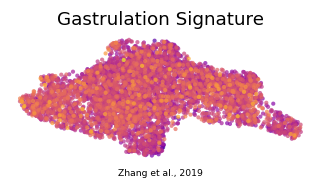

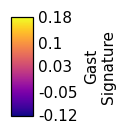

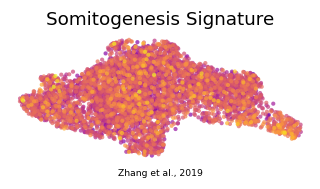

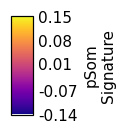

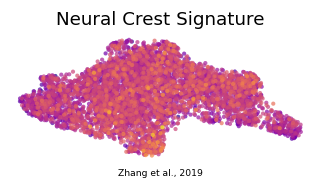

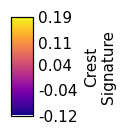

In [4]:
plot=adata.copy(); plot.obsm['X_umap']=plot.obsm['X_umap_lin']
xl=plot.obsm['X_umap']
xlo,xhi=np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi=np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
titles={'Gast':'Gastrulation Signature','pSom':'Somitogenesis Signature','Crest':'Neural Crest Signature'}
for m in ['Gast','pSom','Crest']:
    fig,ax=plt.subplots(figsize=(3.5,1.5))
    sc.pl.umap(plot,color=m,cmap='plasma',alpha=.7,size=30,colorbar_loc=None,
               frameon=False,show=False,ax=ax,title=titles[m])
    ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
    ax.text(.5,-.12,'Zhang et al., 2019',ha='center',transform=ax.transAxes,size=6)
    fig.savefig(os.path.join(pth_fig,f'{m}_signature.pdf'),bbox_inches='tight')
    lo,hi_=float(adata.obs[m].min()),float(adata.obs[m].max())
    ticks=np.round(np.linspace(lo,hi_,5),2)
    fcb=plt.figure(figsize=(.66,1)); cax=fcb.add_axes([.35,.05,.3,.9])
    cb=plt.colorbar(ax.collections[0],cax=cax); cb.ax.tick_params(which='both',size=0)
    cb.set_label(f'{m}\nSignature'); cb.set_ticks(ticks,labels=ticks); cb.solids.set_alpha(1)
    fcb.savefig(os.path.join(pth_cb,f'{m}_colorbar.pdf'),bbox_inches='tight')
    plt.show()
    print('saved',f'{m}_signature.pdf','+ colorbar')

### Gate 2 test 1 — module geography and the (absent) hub
A co-expression hub (branching signature) shows joint Gast&pSom-high enrichment > 1; an organized
inverse gradient (non-branching signature) shows a coherent pseudotime trend. We report the
smoothed module-module correlations, the joint-high enrichment, and the pseudotime gradients.

In [5]:
print('smoothed spatial correlations (geography):')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    print(f'  {a} vs {b}: r = {np.corrcoef(adata.obs[a],adata.obs[b])[0,1]:+.3f}')
pz=(adata.obs['Gast']-adata.obs['Gast'].mean())/adata.obs['Gast'].std()
cz=(adata.obs['pSom']-adata.obs['pSom'].mean())/adata.obs['pSom'].std()
joint=((pz>0.5)&(cz>0.5)).mean(); exp=(pz>0.5).mean()*(cz>0.5).mean()
print(f'\njoint Gast&pSom-high enrichment = {joint/exp:.2f} (>1 = co-expression hub; ~1 = no hub)')
t=adata.obs['t'].values; tn=(t-t.min())/(t.max()-t.min())
print('gradient along pseudotime (Spearman rho on smoothed):')
for sname in ['Gast_sm','pSom_sm','Crest_sm']:
    print(f'  {sname}: rho = {spearmanr(t,adata.obs[sname])[0]:+.3f}')

smoothed spatial correlations (geography):
  Gast_sm vs pSom_sm: r = -0.162
  Crest_sm vs Gast_sm: r = -0.548
  Crest_sm vs pSom_sm: r = -0.578

joint Gast&pSom-high enrichment = 1.00 (>1 = co-expression hub; ~1 = no hub)
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho = -0.481
  pSom_sm: rho = +0.107
  Crest_sm: rho = +0.324


### Gate 2 test 2 — the random-module null (the test the prior attempts skipped)
The decisive check: are the embryonic modules distinguishable from **random gene sets of the same
size**, scored against the same union control pool and smoothed identically? For 200 random draws
we compute the same statistics (Gast–pSom r, Crest-vs-both r, Crest pseudotime gradient). If the
observed embryonic values sit **inside** the null 95% band, the modules carry no
embryonic-specific signal and Gate 2 is NO-GO.

In [6]:
g_ref=feat['union'].loc[feat['union'].isin(adata.var_names)]
pool=g_ref.to_numpy()
sizes={'Gast':int(feat['GSE162534'].isin(adata.var_names).sum()),
       'pSom':int(feat['GSE229103'].isin(adata.var_names).sum()),
       'Crest':int(feat['rRNAModifications'].isin(adata.var_names).sum())}
A=(adata.obsp['connectivities']>0).astype(float); A=A+sp.eye(A.shape[0]); A=sp.diags(1/np.array(A.sum(1)).ravel())@A
def smooth(v):
    v=v.copy()
    for _ in range(3): v=A@v
    return v
rng=np.random.default_rng(0); nrep=200; gp,cvb,cg=[],[],[]
for i in range(nrep):
    Sm={}
    for lab,sz in sizes.items():
        rgs=pd.Series(rng.choice(pool,size=sz,replace=False))
        sc.tl.score_genes(adata,gene_list=rgs,score_name='_rnd',ctrl_as_ref=False,gene_pool=g_ref,random_state=int(rng.integers(1e6)))
        Sm[lab]=smooth(adata.obs['_rnd'].values)
    gp.append(np.corrcoef(Sm['Gast'],Sm['pSom'])[0,1])
    cvb.append((np.corrcoef(Sm['Crest'],Sm['Gast'])[0,1]+np.corrcoef(Sm['Crest'],Sm['pSom'])[0,1])/2)
    cg.append(spearmanr(t,Sm['Crest'])[0])
gp,cvb,cg=map(np.array,(gp,cvb,cg))
obs_gp=np.corrcoef(adata.obs['Gast_sm'],adata.obs['pSom_sm'])[0,1]
obs_cvb=(np.corrcoef(adata.obs['Crest_sm'],adata.obs['Gast_sm'])[0,1]+np.corrcoef(adata.obs['Crest_sm'],adata.obs['pSom_sm'])[0,1])/2
obs_cg=spearmanr(t,adata.obs['Crest_sm'])[0]
def band(x): return f'[{np.percentile(x,2.5):+.3f}, {np.percentile(x,97.5):+.3f}]'
print('RANDOM-MODULE NULL (200 draws from the union pool, same sizes, same smoothing):')
print(f'  Gast-pSom r:      OBS {obs_gp:+.3f} | null mean {gp.mean():+.3f} 95% {band(gp)} | pctile {int((gp<obs_gp).mean()*100)}%')
print(f'  Crest-vs-both r:  OBS {obs_cvb:+.3f} | null mean {cvb.mean():+.3f} 95% {band(cvb)} | pctile {int((cvb<obs_cvb).mean()*100)}%')
print(f'  Crest pt-grad:    OBS {obs_cg:+.3f} | null mean {cg.mean():+.3f} 95% {band(cg)} | pctile {int((cg<obs_cg).mean()*100)}%')
print('\nGast-pSom r and Crest pt-gradient sit INSIDE the null band -> indistinguishable from random modules.')

RANDOM-MODULE NULL (200 draws from the union pool, same sizes, same smoothing):
  Gast-pSom r:      OBS -0.162 | null mean -0.065 95% [-0.873, +0.812] | pctile 48%
  Crest-vs-both r:  OBS -0.563 | null mean -0.029 95% [-0.635, +0.710] | pctile 5%
  Crest pt-grad:    OBS +0.324 | null mean -0.008 95% [-0.773, +0.785] | pctile 72%

Gast-pSom r and Crest pt-gradient sit INSIDE the null band -> indistinguishable from random modules.


### Gate 2 verdict — NO-GO
- Module means at the control-pool noise floor (|mean| ≤ 0.012), 20–40× below real-pattern datasets.
- No Gast/pSom co-expression hub (joint-high enrichment ≈ 1.0) and Gast↔pSom r ≈ 0.
- The Gast–pSom relationship and the Crest pseudotime gradient are **inside** the random-module
  95% null band — no embryonic-specific signal.
- The one extreme statistic (Crest-opposes-both) is a mechanical `score_genes` shared-pool artifact
  (Crest is the largest module) with a null-level pseudotime gradient — static scoring geometry, not
  a developmental gradient.

The organized embryonic pattern is **absent** → **Gate 2 = NO-GO / Gate 3 = NA.** This overturns
the five prior GO calls, which read `score_genes` shared-pool artifacts (and, in -4, a circularly
scoped cycling lobe) as an embryonic axis. We save `signatures.h5ad` and stop the gate chain; the
unconditional expression notebook follows as **04**.

In [7]:
adata.write(os.path.join(pth_out,'signatures.h5ad'))
print('saved signatures.h5ad', adata.shape)
print('GATES: Gate 1 = GO | Gate 2 = NO-GO | Gate 3 = NA')
print('deliverables per S6: 01_preprocessing + 02_manifold + 03_signatures + 04_expression (renumbered)')

saved signatures.h5ad (5645, 14715)
GATES: Gate 1 = GO | Gate 2 = NO-GO | Gate 3 = NA
deliverables per S6: 01_preprocessing + 02_manifold + 03_signatures + 04_expression (renumbered)
